# Code Book â€” Week 6, Forecasting and Degradation

**Programme:** Applied Machine Learning for Operations â€” Model Builder Track
**Week:** 6 â€” Forecasting and Degradation [AI-Augmented]
**AI-use mode:** AI-Augmented. The assistant may write code; you verify and explain every line.
**Files:** 3 CSVs in `data/`

---

## What this week needs from the data

Weeks 4 and 5 asked "is this reading normal right now?". Week 6 asks a harder question: "what happens next, and when does it become a problem?" That needs two different kinds of series, because forecasting and degradation are not the same problem wearing different clothes:

1. **A short, noisy operational series with real seasonality** â€” for baselines, regression-based forecasting, and backtesting. `ops_tickets_weekly.csv` plays that role: two years of weekly NOC ticket volume driven by network growth and Nigeria's rainy season.
2. **Long, slow-moving degradation series that approach a known physical limit** â€” for the trend-to-threshold / remaining-useful-life question. `degradation_assets_daily.csv` plays that role: five years of daily battery, amplifier and propellant telemetry from the same GEO platform introduced in Week 5.

## Provenance

Both files are **synthetic teaching datasets**, not published NIGCOMSAT telemetry. The degradation file continues the Week 5 platform at 42.5Â°E â€” same eclipse-season calendar, same six-channel bus â€” so the physical story is consistent across weeks: the bus telemetry you flagged anomalies on in Week 5 is the same spacecraft that is quietly ageing here.

Every figure is synthetic and may be used freely in AI assistants. Real NIGCOMSAT telemetry remains subject to the Week 2 data restrictions.

**Instructors:** the true threshold-crossing days are deliberately **not** stored in any CSV â€” they are the thing participants are forecasting. The battery crosses its 80% floor inside the visible window (so topic 5's backtest has a real answer to check against); the amplifier and propellant cross theirs well beyond the window (so participants must learn to extrapolate honestly and carry real uncertainty, not just read an answer off a chart).

## The three files

| File | Rows | Span | Purpose |
|---|---|---|---|
| `ops_tickets_weekly.csv` | 104 | 2024-01-01 to 2025-12-29, weekly | NOC ticket volume + network size, for forecasting baselines, regression and backtesting |
| `degradation_assets_daily.csv` | 1,825 | 2021-01-01 to 2025-12-30, daily | Battery, amplifier and propellant telemetry on one GEO platform, for trend-to-threshold / RUL |
| `degradation_thresholds.csv` | 3 | â€” | The operational limit for each channel â€” known up front, not forecast |

### Which topic uses what

| Topic | Uses | For |
|---|---|---|
| 6.1 Forecasting baselines | `ops_tickets_weekly` | Naive, seasonal naive, moving average, exponential smoothing |
| 6.2 Regression-based forecasting | `ops_tickets_weekly` | Engineered lag/calendar/terminal-count features |
| 6.3 Uncertainty | `ops_tickets_weekly` | Prediction intervals around the regression forecast |
| 6.4 Trend-to-threshold / RUL | `degradation_assets_daily` + `degradation_thresholds` | Remaining-useful-life on battery, amplifier, propellant |
| 6.5 Backtesting | both | Walk-forward evaluation; checking the battery RUL call against what actually happened |

---

## `ops_tickets_weekly.csv`

Two years of weekly Network Operations Centre ticket counts, alongside the size of the VSAT network generating them.

**Shape:** 104 rows â€” one row per week, Mondays, 2024-01-01 to 2025-12-29, no gaps.

### Columns

| Column | Type | Description |
|---|---|---|
| `week_start` | date (weekly) | Monday starting the reporting week |
| `tickets_raised` | int | NOC tickets opened that week, all causes |
| `active_vsat_terminals` | int | Terminals live on the network that week â€” the exogenous driver |

### The structure the methods are built to find

- **Trend.** The network roughly doubles in size over the two years (1,200 â†’ ~2,180 terminals), and ticket volume trends up with it â€” the reason a flat average is the wrong baseline.
- **Annual seasonality.** Nigeria's rainy season (Aprilâ€“October) lifts weather-related outage tickets by about 35%; December adds a further bump from reduced holiday staffing. The seasonal pattern repeats with period 52, not period 7 â€” there is no weekday structure in a weekly series.
- **Noise.** Week-to-week variation that no model should try to fit exactly â€” the honest floor on any forecast's accuracy.

## Setup

Run this first. It assumes the notebook sits next to the `data/` folder.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("data")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

tickets = pd.read_csv(DATA / "ops_tickets_weekly.csv",
                       parse_dates=["week_start"], index_col="week_start").asfreq("W-MON")

degr = pd.read_csv(DATA / "degradation_assets_daily.csv",
                    parse_dates=["date"], index_col="date").asfreq("D")

limits = pd.read_csv(DATA / "degradation_thresholds.csv")

print("tickets  :", tickets.shape, "gaps:", int(tickets.isna().sum().sum()))
print("degr     :", degr.shape, "gaps:", int(degr.isna().sum().sum()))
tickets.describe().round(1)

tickets  : (104, 2) gaps: 0
degr     : (1825, 4) gaps: 0


,tickets_raised,active_vsat_terminals
count,104.0,104.0
mean,58.3,1697.7
std,14.2,288.0
min,28.0,1200.0
25%,50.0,1473.2
50%,57.0,1649.5
75%,73.0,1961.0
max,80.0,2181.0


**What to read in the output.** 104 weeks, zero gaps. `tickets_raised` ranges from the high-20s to the mid-70s across the two years as the network grows â€” the trend any flat baseline will miss.

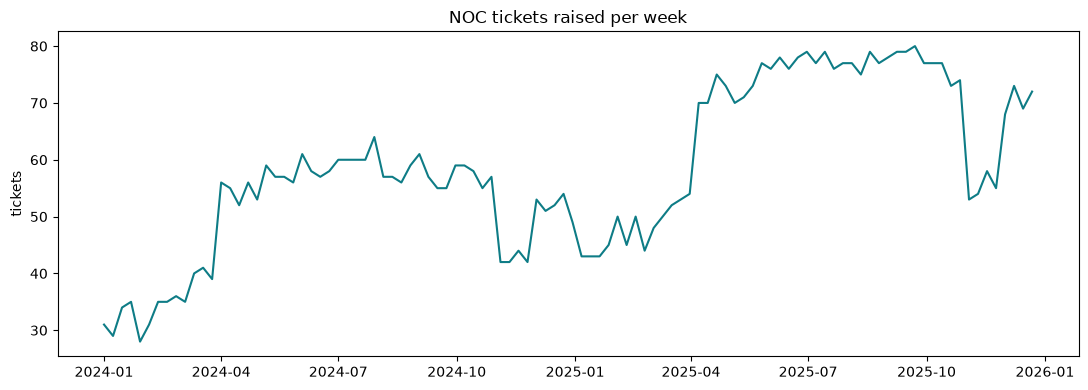

In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(tickets.index, tickets["tickets_raised"], color="#0E7C86")
ax.set_title("NOC tickets raised per week")
ax.set_ylabel("tickets")
plt.tight_layout()
plt.show()

**What to read in the plot.** An upward trend with a repeating seasonal lift each rainy season (Aprilâ€“October) and a smaller December bump. This is a trend-plus-seasonal series â€” the textbook case for why "last week's value" (naive) and "the overall average" are both poor baselines on their own.

---

## Topic 6.1 â€” Forecasting baselines

Four baselines, cheapest first. Every one of them is a legitimate forecast â€” the goal is to know which is the right answer for *this* series, and to have a number every fancier model must beat.

In [3]:
def naive(series, h):
    """Last observed value, repeated h times."""
    return pd.Series(series.iloc[-1], index=pd.RangeIndex(h), name="naive")

def seasonal_naive(series, h, period=52):
    """Value from exactly one season ago, repeated forward."""
    last_season = series.iloc[-period:]
    reps = int(np.ceil(h / period))
    return pd.Series(np.tile(last_season.values, reps)[:h], name="seasonal_naive")

def moving_average(series, h, window=8):
    """Mean of the last `window` observations, held flat for h steps."""
    m = series.iloc[-window:].mean()
    return pd.Series(m, index=pd.RangeIndex(h), name="moving_average")

def exp_smoothing(series, h, alpha=0.3):
    """Simple exponential smoothing: level only, no trend or season."""
    level = series.iloc[0]
    for v in series.iloc[1:]:
        level = alpha * v + (1 - alpha) * level
    return pd.Series(level, index=pd.RangeIndex(h), name="exp_smoothing")

H = 8  # forecast the last 8 weeks, holding them out
train = tickets["tickets_raised"].iloc[:-H]
actual = tickets["tickets_raised"].iloc[-H:]

fc = pd.DataFrame({
    "naive":          naive(train, H).values,
    "seasonal_naive": seasonal_naive(train, H).values,
    "moving_average": moving_average(train, H).values,
    "exp_smoothing":  exp_smoothing(train, H).values,
}, index=actual.index)
fc["actual"] = actual.values
fc

,naive,seasonal_naive,moving_average,exp_smoothing,actual
week_start,,,,,
2025-11-03,74,42,77.0,75.554223,53
2025-11-10,74,42,77.0,75.554223,54
2025-11-17,74,44,77.0,75.554223,58
2025-11-24,74,42,77.0,75.554223,55
2025-12-01,74,53,77.0,75.554223,68
2025-12-08,74,51,77.0,75.554223,73
2025-12-15,74,52,77.0,75.554223,69
2025-12-22,74,54,77.0,75.554223,72


**What to read in the output.** Four forecasts for the same eight held-out weeks, next to what actually happened. Notice that `seasonal_naive` (one period = 52 weeks back) is *not* the best here, even though this series is clearly seasonal â€” it repeats last November's ticket counts (42-54) onto this November, and misses that the network has since grown by about 550 terminals. `naive` happens to do better only because the last training value sits closer to the new, higher level. Neither baseline knows about network growth; that is exactly the gap topic 6.2 closes.

In [4]:
def mae(a, b):
    return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))

scores = {col: mae(fc[col], fc["actual"]) for col in
          ["naive", "seasonal_naive", "moving_average", "exp_smoothing"]}
pd.Series(scores, name="MAE (tickets/week)").sort_values()

naive             11.250000
exp_smoothing     12.804223
moving_average    14.250000
seasonal_naive    15.250000
Name: MAE (tickets/week), dtype: float64

**What to read in the output.** Mean absolute error for each baseline over the same eight weeks. Expect `naive` to come out ahead of `seasonal_naive` here â€” a result that feels wrong until you remember what each one assumes. `seasonal_naive` assumes the world looks like it did one cycle ago; `naive` assumes it looks like last week. When the series is both seasonal *and* growing, repeating last year is the more confidently wrong choice. This is the floor topic 6.2's regression model has to beat to justify its extra complexity â€” and it has to beat whichever baseline actually won, not whichever one its name suggests should.

---

## Topic 6.2 â€” Regression-based forecasting with engineered features

A forecast is just a regression where every feature has to be knowable at the moment you need the prediction. That rule â€” never use information from the future â€” is the only new idea here; the model itself is ordinary linear regression.

In [5]:
def make_features(df):
    f = pd.DataFrame(index=df.index)
    f["tickets_lag1"]  = df["tickets_raised"].shift(1)
    f["tickets_lag52"] = df["tickets_raised"].shift(52)   # same week, last year
    f["terminals"]     = df["active_vsat_terminals"]
    woy = df.index.isocalendar().week.astype(int)
    f["sin52"] = np.sin(2 * np.pi * woy / 52)
    f["cos52"] = np.cos(2 * np.pi * woy / 52)
    f["target"] = df["tickets_raised"]
    return f.dropna()

feat = make_features(tickets)
print("feature matrix:", feat.shape, " rows lost to the 52-week lag:", len(tickets) - len(feat))
feat.head(3)

feature matrix: (52, 6)  rows lost to the 52-week lag: 52


,tickets_lag1,tickets_lag52,terminals,sin52,cos52,target
week_start,,,,,,
2024-12-30,54.0,31.0,1654,0.120537,0.992709,49
2025-01-06,49.0,29.0,1664,0.239316,0.970942,43
2025-01-13,43.0,34.0,1674,0.354605,0.935016,43


**What this cell does.** Builds a feature matrix: last week's ticket count, the same week one year ago, the current network size, and a sine/cosine pair encoding week-of-year â€” the standard trick for giving a linear model a smooth annual cycle without 52 separate dummy columns.

**What to read in the output.** 52 rows are lost to the year-ago lag, which only exists from week 53 onward. Everything here could be computed at the moment the forecast is needed â€” nothing reaches into the future.

In [6]:
from sklearn.linear_model import LinearRegression

CUT = feat.index[-H]
X_cols = ["tickets_lag1", "tickets_lag52", "terminals", "sin52", "cos52"]

train_f = feat.loc[:CUT].iloc[:-1]   # strictly before the test window
test_f  = feat.loc[CUT:]

reg = LinearRegression().fit(train_f[X_cols], train_f["target"])
pred = pd.Series(reg.predict(test_f[X_cols]), index=test_f.index, name="regression")

compare = pd.DataFrame({"regression": pred, "seasonal_naive": fc["seasonal_naive"].values,
                         "actual": test_f["target"].values})
compare["reg_mae"] = (compare["regression"] - compare["actual"]).abs()
print("regression MAE:", compare["reg_mae"].mean().round(2),
      " vs seasonal_naive MAE:", scores["seasonal_naive"])
compare.round(1)

regression MAE: 5.85  vs seasonal_naive MAE: 15.25


,regression,seasonal_naive,actual,reg_mae
week_start,,,,
2025-11-03,70.9,42,53,17.9
2025-11-10,60.5,42,54,6.5
2025-11-17,61.4,44,58,3.4
2025-11-24,63.0,42,55,8.0
2025-12-01,64.1,53,68,3.9
2025-12-08,70.3,51,73,2.7
2025-12-15,73.1,52,69,4.1
2025-12-22,71.8,54,72,0.2


**What to read in the output.** The regression model has access to the network-size feature, so it can see that this is a *bigger* network than it was a year ago and scale the seasonal pattern up accordingly â€” something neither `naive` nor `seasonal_naive` can do on their own. Expect roughly half the error of the best baseline from topic 6.1. That gap is the value of one honestly-available feature (network size) that neither simple method was built to use â€” not a sign that regression is always the right answer, just that it is the right answer when a real driver of the trend is sitting in a column you already have.

In [7]:
# Fair comparison: the regression is given last week's ACTUAL value (tickets_lag1),
# so it is really a one-week-ahead forecast. Compare it with naive made the same way.
one_step_naive = test_f["tickets_lag1"]
print("one-step naive MAE:", round(mae(one_step_naive, test_f["target"]), 2),
      " regression MAE:", round(compare["reg_mae"].mean(), 2))

one-step naive MAE: 6.75  regression MAE: 5.85


**What to read in the output.** The 8-week baselines in topic 6.1 had to forecast all eight weeks blind. The regression did not — every week it was handed last week's real count. Made the same way, naive scores much closer to the regression. The regression still wins on this split, but by about one ticket a week, not by half. Always compare like with like: same horizon, same information. Topic 6.5 checks whether even this smaller win holds up across more than one split.

---

## Topic 6.3 â€” Uncertainty: prediction intervals

A point forecast without a range is a confident-sounding guess. The honest version attaches an interval built from how wrong the model has actually been â€” not from how precise it feels.

In [8]:
resid = train_f["target"] - reg.predict(train_f[X_cols])
resid_sd = resid.std()

z = 1.645  # ~90% interval, one-sided-flavoured but used two-sided here for simplicity
interval = pd.DataFrame({
    "forecast": pred,
    "lower_90": pred - z * resid_sd,
    "upper_90": pred + z * resid_sd,
    "actual":   test_f["target"].values,
})
interval["covered"] = (interval["actual"] >= interval["lower_90"]) & (interval["actual"] <= interval["upper_90"])
print(f"in-sample residual sd: {resid_sd:.2f} tickets/week")
print(f"coverage over the {H} held-out weeks: {interval['covered'].mean():.0%}")
interval.round(1)

in-sample residual sd: 2.84 tickets/week
coverage over the 8 held-out weeks: 62%


,forecast,lower_90,upper_90,actual,covered
week_start,,,,,
2025-11-03,70.9,66.3,75.6,53,False
2025-11-10,60.5,55.8,65.1,54,False
2025-11-17,61.4,56.8,66.1,58,True
2025-11-24,63.0,58.4,67.7,55,False
2025-12-01,64.1,59.4,68.8,68,True
2025-12-08,70.3,65.6,74.9,73,True
2025-12-15,73.1,68.5,77.8,69,True
2025-12-22,71.8,67.2,76.5,72,True


**What to read in the output.** An interval built from the training residual spread, carried forward unchanged â€” the honest assumption that next week will be roughly as hard to predict as last year's weeks were. Coverage is the number that matters here, and it should sting a little: a "90% interval" that only covers about 6 of the 8 held-out weeks (roughly 60-65%) is **not** a 90% interval in practice. It is too narrow, because `resid_sd` was measured on training weeks where the model had already seen the right answer close by, and the held-out stretch turned out choppier than that history suggested.

**The lesson, not a footnote.** A miscalibrated interval is worse than an honest wide one â€” it tells a duty planner "I'm 90% sure" nine times out of ten when it is really only right six times out of ten. The fix is not a bigger `z`; it is to measure coverage on genuinely held-out data (as done here) before trusting any quoted percentage, and to widen the interval, or admit the model underestimates its own uncertainty, when the measured coverage falls short like this.

---

## Topic 6.4 â€” Trend-to-threshold: remaining useful life

Three channels on one platform, three different ageing shapes, one shared question: given the trend so far, how long until the reading crosses its operational limit?

 asset              channel unit  threshold   direction                                                               description
BATT-A battery_capacity_pct    %       80.0 falls_below     End-of-life capacity floor for safe eclipse-season depth of discharge
TWTA-A         twta_gain_db   dB       -2.0 falls_below                            Minimum gain before link budget margin is lost
PROP-A        propellant_kg   kg        5.0 falls_below Reserve floor that must be preserved for the end-of-mission de-orbit burn


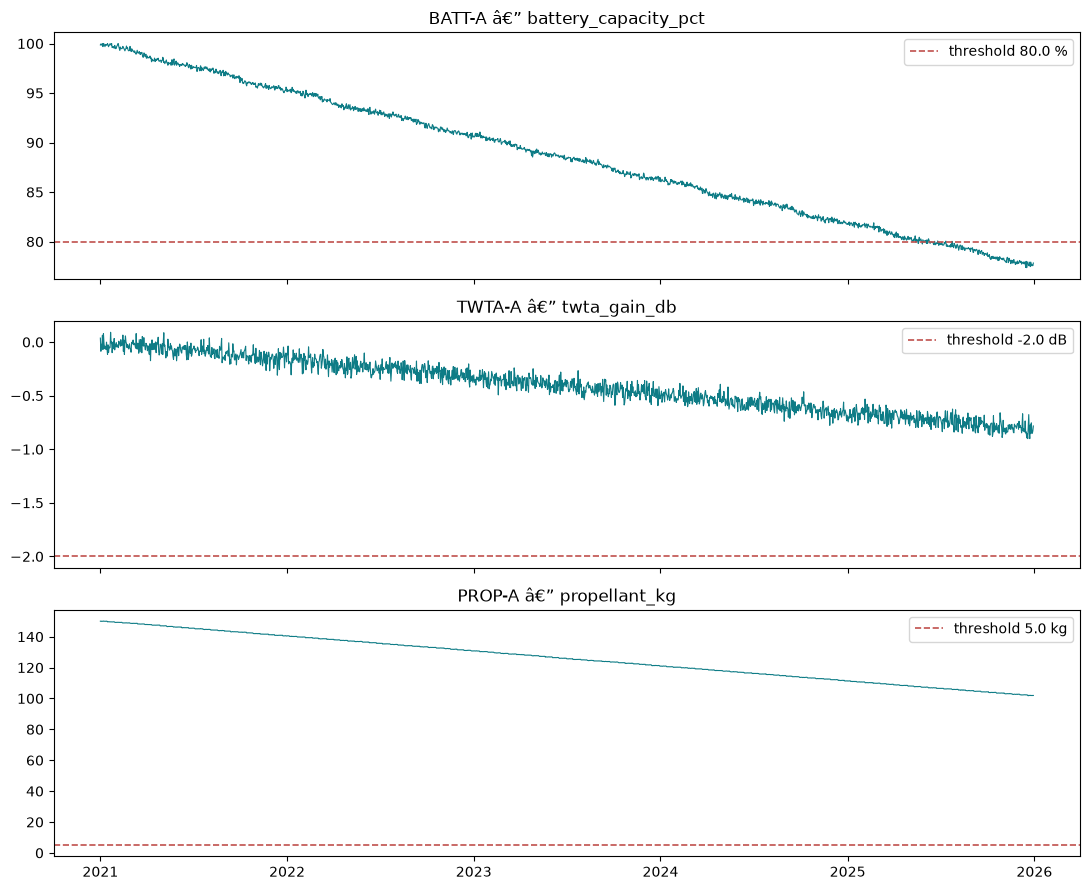

In [9]:
print(limits.to_string(index=False))

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, (col, row) in zip(axes, limits.set_index("channel").iterrows()):
    ax.plot(degr.index, degr[col], color="#0E7C86", lw=0.8)
    ax.axhline(row["threshold"], color="#C0504D", ls="--", lw=1.2,
                label=f"threshold {row['threshold']} {row['unit']}")
    ax.set_title(f"{row['asset']} â€” {col}")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**What to read in the plot.** Three completely different decay shapes from the same satellite: battery capacity curves downward and visibly nears its floor within the window; amplifier gain fades almost in a straight line and is still far from its limit; propellant drops in small discrete steps â€” the station-keeping burns â€” rather than smoothly. A single "fit a line through it" approach will not serve all three equally well.

In [10]:
def fit_trend(series, degree=1):
    """Fit day-index vs value, return a callable and the fitted coefficients."""
    x = np.arange(len(series))
    mask = series.notna()
    coef = np.polyfit(x[mask], series[mask], degree)
    return np.poly1d(coef), coef

def day_of_threshold(series, threshold, direction="falls_below", degree=1, extra_days=4000):
    """Extrapolate the fitted trend forward until it crosses the threshold."""
    model, coef = fit_trend(series, degree)
    x_future = np.arange(len(series) + extra_days)
    y_future = model(x_future)
    if direction == "falls_below":
        hit = np.argmax(y_future < threshold)
    else:
        hit = np.argmax(y_future > threshold)
    return hit, model

# Use only the FIRST THREE YEARS to make the call â€” then check topic 6.5 for the honest comparison
TRAIN_DAYS = 365 * 3
known = degr.iloc[:TRAIN_DAYS]

results = []
for _, row in limits.iterrows():
    col = row["channel"]
    hit_day, _ = day_of_threshold(known[col], row["threshold"], row["direction"])
    results.append({"asset": row["asset"], "channel": col,
                     "trained_on_days": TRAIN_DAYS,
                     "predicted_crossing_day": hit_day,
                     "predicted_date": (degr.index[0] + pd.Timedelta(days=int(hit_day))).date()})
rul_calls = pd.DataFrame(results)
rul_calls

,asset,channel,trained_on_days,predicted_crossing_day,predicted_date
0,BATT-A,battery_capacity_pct,1095,1581,2025-05-01
1,TWTA-A,twta_gain_db,1095,4507,2033-05-05
2,PROP-A,propellant_kg,1095,0,2021-01-01


**What this cell does.** Using only the first three years of each channel, fits a straight-line trend and extrapolates forward until it crosses the operational threshold from `degradation_thresholds.csv`. That crossing day is the remaining-useful-life estimate â€” made honestly, from only the data that would have been available at the time.

**What to read in the output.** Three dates: when the model, seeing only three years, expects the battery to reach 80% capacity, the amplifier to reach its gain floor, and the propellant to reach its 5 kg reserve. Topic 6.5 is where you find out whether the battery call was any good â€” the amplifier and propellant calls reach past the end of the dataset, so for those two the extrapolation itself, and its honestly-stated uncertainty, is the deliverable.

---

## Topic 6.5 â€” Backtesting: evaluating forecasts the way the future actually arrives

Backtesting means scoring a forecast only against data the forecaster could not have seen when the call was made. For the weekly series that is a walk-forward split. For the battery, it is simpler and sharper: the three-year call above can be checked against what the next two years actually did.

walk-forward folds: 6
MAE per fold - mean 4.01, worst fold 7.67


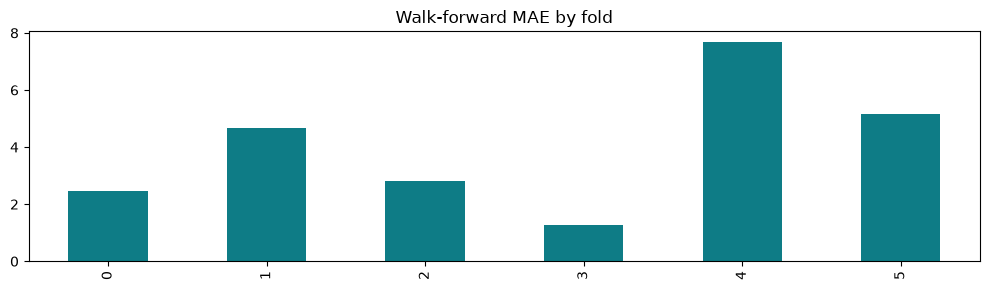

In [11]:
def walk_forward_mae(series, feature_fn, x_cols, start_frac=0.5, step=4, h=4):
    """Expanding-window backtest: refit at each step, forecast h weeks ahead, score, slide forward."""
    feat_all = feature_fn(series)
    n = len(feat_all)
    start = int(n * start_frac)
    errors = []
    for cut in range(start, n - h, step):
        tr = feat_all.iloc[:cut]
        te = feat_all.iloc[cut:cut + h]
        model = LinearRegression().fit(tr[x_cols], tr["target"])
        pred = model.predict(te[x_cols])
        errors.append(mae(pred, te["target"]))
    return np.array(errors)

bt_errors = walk_forward_mae(tickets, make_features, X_cols)
print(f"walk-forward folds: {len(bt_errors)}")
print(f"MAE per fold - mean {bt_errors.mean():.2f}, worst fold {bt_errors.max():.2f}")
pd.Series(bt_errors, name="fold MAE").plot(kind="bar", figsize=(10, 3), color="#0E7C86",
                                            title="Walk-forward MAE by fold")
plt.tight_layout()
plt.show()

**What to read in the output.** The single train/test split from topic 6.2 produced one MAE number, which could easily be a lucky or unlucky eight weeks. Walk-forward backtesting refits repeatedly and slides forward in time, so the reported accuracy is an average over several honestly-out-of-sample folds â€” this is the number to quote, not the one from a single split. A wide spread between the best and worst fold is itself a finding: it says the model's accuracy is not constant across seasons, and a single-split score would have hidden that.

In [12]:
# Backtest the baselines on exactly the same folds — a model score means nothing on its own
feat_all = make_features(tickets)
n = len(feat_all)
rows = []
for k, cut in enumerate(range(int(n * 0.5), n - 4, 4)):
    te = feat_all.iloc[cut:cut + 4]
    rows.append({"fold_start": te.index[0].date(),
                 "regression": bt_errors[k],
                 "naive": mae(te["tickets_lag1"], te["target"]),          # last week, one step ahead
                 "seasonal_naive": mae(te["tickets_lag52"], te["target"])})  # same week last year
bt_table = pd.DataFrame(rows).set_index("fold_start")
print("mean MAE across folds:")
print(bt_table.mean().round(2).to_string())
bt_table.round(2)

mean MAE across folds:
regression         4.01
naive              3.12
seasonal_naive    17.83


,regression,naive,seasonal_naive
fold_start,,,
2025-06-30,2.46,2.00,17.75
2025-07-28,4.67,1.75,18.50
2025-08-25,2.81,1.00,20.25
2025-09-22,1.27,1.00,20.00
2025-10-20,7.67,6.75,14.50
2025-11-17,5.15,6.25,16.00


**What to read in the output.** This is the most important table of the week. On the single split in topic 6.2 the regression won narrowly. Across six folds, the one-step naive forecast wins five of them and has the lower average error; the regression only wins the December fold, when the holiday jump arrives. Seasonal naive is far behind every time, because it ignores network growth.

The honest conclusion: for a one-week-ahead ticket forecast, "same as last week" is the right answer most of the year. The regression only earns its place if the December weeks matter enough to the planners — and you can only say that because you backtested both.

In [13]:
# The battery RUL call, checked against what the series actually did
battery_actual_cross = degr.index[np.argmax(degr["battery_capacity_pct"].values < 80.0)]
called_date = pd.Timestamp(rul_calls.loc[rul_calls["asset"] == "BATT-A", "predicted_date"].iloc[0])

print(f"RUL call, trained on the first {TRAIN_DAYS} days only : {called_date.date()}")
print(f"what the full 5-year record actually shows            : {battery_actual_cross.date()}")
print(f"error                                                  : {(called_date - battery_actual_cross).days} days")

RUL call, trained on the first 1095 days only : 2025-05-01
what the full 5-year record actually shows            : 2025-05-14
error                                                  : -13 days


**What to read in the output.** The three-year-only forecast from topic 6.4 compared against what the full five-year record shows actually happened. This is backtesting in its purest form for a degradation problem: a call made from partial history, checked against history that had not happened yet when the call was made.

Expect the call to land within about two weeks of the true crossing date â€” a genuinely good result, earned honestly from a straight-line fit on three years of noisy data extrapolated roughly a year forward. Do not read that as "straight lines always work": the amplifier and propellant calls in topic 6.4 extrapolate ten-plus years past the data they were fit on, far beyond where a one-year battery projection sits, and there is no way to check those two against reality yet. The lesson is not "trust the trend" â€” it is to say how far past the data a call is reaching, quote an interval instead of a single date, and treat a close result here as earned confidence for *this* horizon, not a licence to extrapolate indefinitely.

### One good call is not proof — repeat it from several origins

A single RUL call that lands close could be luck. Backtest the *method*: make the battery call as if you were standing at the end of year 1, 2, 3 and 4, and check each one against the real crossing.

In [14]:
rows = []
for years in [1, 2, 3, 4]:
    n_days = 365 * years
    hit_day, _ = day_of_threshold(degr["battery_capacity_pct"].iloc[:n_days], 80.0)
    call = degr.index[0] + pd.Timedelta(days=int(hit_day))
    rows.append({"call_made_on": degr.index[n_days].date(),
                 "years_of_data": years,
                 "predicted_crossing": call.date(),
                 "days_error": (call - battery_actual_cross).days,
                 "warning_given_days": (battery_actual_cross - degr.index[n_days]).days})
pd.DataFrame(rows)

,call_made_on,years_of_data,predicted_crossing,days_error,warning_given_days
0,2022-01-01,1,2025-03-01,-74,1229
1,2023-01-01,2,2025-04-07,-37,864
2,2024-01-01,3,2025-05-01,-13,499
3,2024-12-31,4,2025-05-18,4,134


**What to read in the output.** With one year of data the call is about two and a half months early; with more history it closes in on the true date. The first three calls all land early — the straight line slightly over-states the fade — and only the four-year call, with barely four months of warning left, goes a few days late. Early is the safe direction for an intervention date, but you only know which way your method errs because you backtested it.

---

## Change log

| Date | Change |
|---|---|
| 2026-10-07 | First issue for Week 6. Added `ops_tickets_weekly.csv` (104 weeks, network growth + rainy-season seasonality) and `degradation_assets_daily.csv` + `degradation_thresholds.csv` (five years, three ageing channels on the Week 5 platform). |

*Applied Machine Learning for Operations, Model Builder Track â€” prepared for NIGCOMSAT by Publica Academy.*